In [5]:
import tensorflow as tf
import numpy as np
import os
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [2]:
DATASET_PATH = './Dataset'
images = []

In [6]:
for image in os.listdir(DATASET_PATH):
    image_path = os.path.join(DATASET_PATH, image)
    image = load_img(image_path, target_size=(64, 64))
    image = img_to_array(image)
    image = image/255.0
    images.append(image)

In [10]:
images = np.array(images)
print(images.shape)

(4948, 64, 64, 3)


In [ ]:
images = np.reshape(images, (images.shape[0], 64 * 64 * 3))
print(images.shape)

(4948, 12288)


In [14]:
train_size = int(len(images) * 0.7)
images = tf.random.shuffle(images, seed=67)

train_data = images[:train_size]
test_data = images[train_size:]

In [22]:
class RBM():
    def __init__(self, input_size, output_size, lr=0.001, batch_size=32):
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = lr
        self.batch_size = batch_size
        
        self.weight = tf.zeros([input_size, output_size], np.float32)
        self.hidden_bias = tf.zeros([output_size], np.float32)
        self.visible_bias = tf.zeros([input_size], np.float32)
    
    def probability_h_given_v(self, visible, weight, hidden_bias):
        return tf.nn.sigmoid(tf.matmul(visible, weight) + hidden_bias)
        # [1,3] * [3,9] = [1,9] + [1,9] -> Hidden
    
    def probability_v_given_h(self, hidden, weight, visible_bias):
        return tf.nn.sigmoid(tf.matmul(hidden, tf.transpose(weight)) + visible_bias)
        # [1,3] * [9,3] = [1,3] + [,3] -> Visible
    
    def sample_probability(self, prob):
        return tf.nn.relu(
            tf.sign(
                prob - tf.random.uniform(tf.shape(prob))
            )
        )
    
    def update_weight_and_bias(self, positive_gradient, negative_gradient, v0, h0, v1, h1):
        self.weight = self.weight + self.learning_rate * (positive_gradient - negative_gradient) / tf.dtypes.cast(tf.shape(v0)[0], tf.float32)

        self.visible_bias = self.visible_bias + self.learning_rate * (tf.reduce_mean(v0 - v1, 0))
        
        self.hidden_bias = self.hidden_bias + self.learning_rate * (tf.reduce_mean(h0 - h1, 0))
    
    def train(self, x_train, epochs=100):
        losses = []
        train_data = tf.data.Dataset.from_tensor_slices(x_train)
        train_data = train_data.batch(self.batch_size)
        
        for epoch in range(epochs):
            print(f"Epoch {epoch+1}/{epochs}")
            
            for batch in train_data:
                h0 = self.sample_probability(self.probability_h_given_v(batch, self.weight, self.hidden_bias))
                
                v1 = self.sample_probability(self.probability_v_given_h(h0, self.weight, self.visible_bias)) 
                
                h1 = self.probability_h_given_v(v1, self.weight, self.hidden_bias)   
                
                positive_gradient = tf.matmul(tf.transpose(batch), h0)
                negative_gradient = tf.matmul(tf.transpose(v1), h1)
                
                self.update_weight_and_bias(positive_gradient, negative_gradient, batch, h0, v1, h1)
            
            loss = tf.reduce_mean(tf.square(batch-v1))
            print(f"Loss: {loss}")
            losses.append(loss)
        
        return losses

    def rbm_reconstruction(self, x):
        h = self.probability_h_given_v(x, self.weight, self.hidden_bias)
        reconstruct = self.probability_v_given_h(h, self.weight, self.visible_bias)
        
        return reconstruct

In [17]:
INPUT_SIZE = train_data.shape[1]

In [18]:
model = RBM(INPUT_SIZE, 6767)
losses = model.train(train_data, 100)

Epoch 1/100
Loss: 0.16253168880939484
Epoch 2/100
Loss: 0.1466560661792755
Epoch 3/100
Loss: 0.13247421383857727
Epoch 4/100
Loss: 0.13024047017097473
Epoch 5/100
Loss: 0.12423132359981537
Epoch 6/100
Loss: 0.12361535429954529
Epoch 7/100
Loss: 0.12184290587902069
Epoch 8/100
Loss: 0.12103193253278732
Epoch 9/100
Loss: 0.11898493766784668
Epoch 10/100
Loss: 0.11804816871881485
Epoch 11/100
Loss: 0.11734515428543091
Epoch 12/100
Loss: 0.11876823753118515
Epoch 13/100
Loss: 0.11740341782569885
Epoch 14/100
Loss: 0.11559540778398514
Epoch 15/100
Loss: 0.11491318792104721
Epoch 16/100
Loss: 0.11601977050304413
Epoch 17/100
Loss: 0.11380577087402344
Epoch 18/100
Loss: 0.11325786262750626
Epoch 19/100
Loss: 0.11365682631731033
Epoch 20/100
Loss: 0.11220502853393555
Epoch 21/100
Loss: 0.11244821548461914
Epoch 22/100
Loss: 0.11182264983654022
Epoch 23/100
Loss: 0.11017385125160217
Epoch 24/100
Loss: 0.10955754667520523
Epoch 25/100
Loss: 0.11062916368246078
Epoch 26/100
Loss: 0.11012438684701

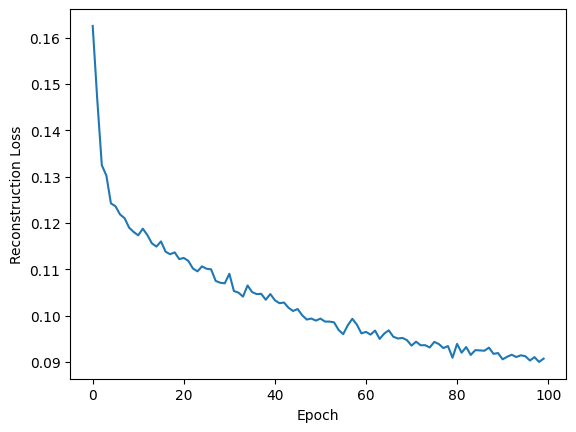

In [19]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.show()

In [40]:
reconstruction = model.rbm_reconstruction(test_data)

AttributeError: 'RBM' object has no attribute 'rbm_reconstruction'

C:\Users\prk\AppData\Local\Temp\ipykernel_13552\3432051650.py:5: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(2, 5, i+6)


NameError: name 'reconstruction' is not defined

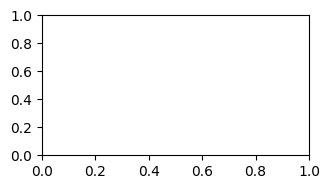

In [38]:
plt.figure(figsize=(20,4))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(tf.reshape(test_data[i], [64,64,3]))
    plt.subplot(2, 5, i+6)
    plt.imshow(tf.reshape(reconstruction[i], [64, 64, 3]))

plt.show()